# 11. Optimizing over a neural-network surrogate

A common workflow: fit a small neural network to simulation or experimental data, then find the input that minimizes the network output.
The network is a *surrogate*: a cheap, differentiable stand-in for an expensive or unknown function, and once trained it is just a fixed
formula in its inputs. Minimizing that formula is still a hard problem. A network with smooth activations is nonconvex in its inputs and
generally has several local minima, so a gradient method started at one point finds one of them, with no indication of whether a better one exists.
To get a *global* answer, with a certificate, the network has to be part of a global optimization model, and the branch-and-bound solver needs
valid lower bounds of the network output over boxes of inputs [schweidtmann2019deterministic].

We train a small tanh MLP (2 inputs, two hidden layers of 8 neurons, 1 output) in JAX, then minimize its output over the box $[-1.5, 1.5]^2$.

**The training data are synthetic**: 400 uniform random points of $y = \sin(3x_1)\cos(2x_2) + 0.3(x_1^2 + x_2^2)$. The network is a stand-in for any fitted surrogate.

The same network can be written as an optimization model in two ways, and the difference matters for the solvers:

* **reduced space**: only the 2 inputs are variables, and the network is one nested expression in them. This is what jaxglobal does with the network's own JAX function;
* **full space**: every pre-activation and activation is a variable, linked by one equality constraint per neuron. This is the usual way to hand a network to an algebraic-modelling solver.

Models compared:
* jaxglobal: the trained network's own forward function, with and without `crown=True` (CROWN backward linear bounds [zhang2018efficient] as an extra lower bound);
* Pyomo reduced space: the network written as one nested expression in the 2 input variables;
* Pyomo full space: one variable per pre-activation and activation, one constraint per neuron;
* OMLT (the Pyomo ecosystem's package for this) [ceccon2022omlt] in both formulations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo

from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table  # jaxglobal is imported after the training (it enables float64)

import jax
import jax.numpy as jnp
import optax

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})

## The network and its training

With $h^{(0)} = x \in \mathbb{R}^2$, the network computes, layer by layer,

$$ z^{(l)} = W^{(l)\top} h^{(l-1)} + b^{(l)}, \qquad h^{(l)} = \tanh\big(z^{(l)}\big), \qquad l = 1, 2, $$

$$ f(x) = W^{(3)\top} h^{(2)} + b^{(3)}, $$

with $W^{(1)} \in \mathbb{R}^{2\times 8}$, $W^{(2)} \in \mathbb{R}^{8\times 8}$, $W^{(3)} \in \mathbb{R}^{8\times 1}$ and biases of matching size,
$2\cdot 8 + 8 + 8\cdot 8 + 8 + 8 + 1 = 105$ parameters $\theta$ in all. $z^{(l)}$ are the *pre-activations*; `net` below is exactly these
equations (with row vectors, `x @ W + b`). The weights start from a scaled normal distribution and the biases at zero, and training
minimizes the mean squared error over the $N = 400$ training points,

$$ \min_\theta \; L(\theta) = \frac1N \sum_{k=1}^{N} \big(f_\theta(x_k) - y_k\big)^2, $$

with 3000 full-batch Adam steps (learning rate $10^{-2}$, `optax`).

In [2]:
def target(X):
    return jnp.sin(3 * X[:, 0]) * jnp.cos(2 * X[:, 1]) + 0.3 * (X[:, 0] ** 2 + X[:, 1] ** 2)


sizes = [2, 8, 8, 1]
key = jax.random.PRNGKey(0)
params = []
for i in range(len(sizes) - 1):
    key, k = jax.random.split(key)
    params.append((jax.random.normal(k, (sizes[i], sizes[i + 1])) / np.sqrt(sizes[i]), jnp.zeros(sizes[i + 1])))


def net(params, x):
    for W, b in params[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = params[-1]
    return (x @ W + b)[..., 0]


Xtr = jax.random.uniform(jax.random.PRNGKey(1), (400, 2), minval=-1.5, maxval=1.5)
ytr = target(Xtr)
loss = lambda p: jnp.mean((net(p, Xtr) - ytr) ** 2)
opt = optax.adam(1e-2)
state = opt.init(params)


@jax.jit
def train_step(p, s):
    l, g = jax.value_and_grad(loss)(p)
    u, s = opt.update(g, s)
    return optax.apply_updates(p, u), s, l


hist = []  # the loss before each step, for the plot below (recording it does not change the training)
for i in range(3000):
    params, state, l = train_step(params, state)
    hist.append(l)
P = [(np.asarray(W, dtype=float), np.asarray(b, dtype=float)) for W, b in params]
LO, HI = -1.5, 1.5
print(f"training MSE {float(l):.2e}; parameters: {sum(W.size + b.size for W, b in P)}; training dtype: {Xtr.dtype}")

training MSE 3.38e-03; parameters: 105; training dtype: float32


**A note on reproducibility.** The seeds above are fixed, and with a given JAX version on a given machine the training is deterministic: two runs give bit-identical weights.
The fixed seed does not make it reproducible across JAX versions, however. The seed fixes the random numbers (the initial weights and the 400 training points), but 3000 Adam steps are sensitive to the last bit of every operation, and XLA's CPU kernels (fusion, summation order, the `tanh` implementation) change between releases and can differ between CPUs.
The precision matters too: the training runs in JAX's default single precision (the dtype is printed above), because jaxglobal, which switches JAX to double precision, is first imported after it. Training in double precision gives a different network.
Earlier stored outputs of this notebook came from an earlier JAX and show a different training MSE and a slightly different minimum, so every number below changes from version to version. The comparisons and conclusions do not.
Bit-for-bit reproducibility would require saving the trained weights to a file and loading them instead of retraining. We have not done that, so the outputs are tied to the JAX version that produced them.

The left panel shows the target and the training points, the middle one the trained network. The network is a smooth fit, not a copy of the
target, and it is the function we optimize from here on. The marked points are the local minima of $f$ on the box, found by a local solver
(L-BFGS-B) started from a $7\times 7$ grid of points: the star is the best of them, the white dots are the others (some lie on the boundary of the box).
A local solver started in the wrong basin stops at one of the white dots. The right panel is the training loss; the spikes are
Adam overshooting and recovering, which is common at a fixed learning rate of this size.

6 distinct local minima from 49 starts; values: -0.9388, -0.3679, -0.3409, -0.3070, 0.0802, 0.1525


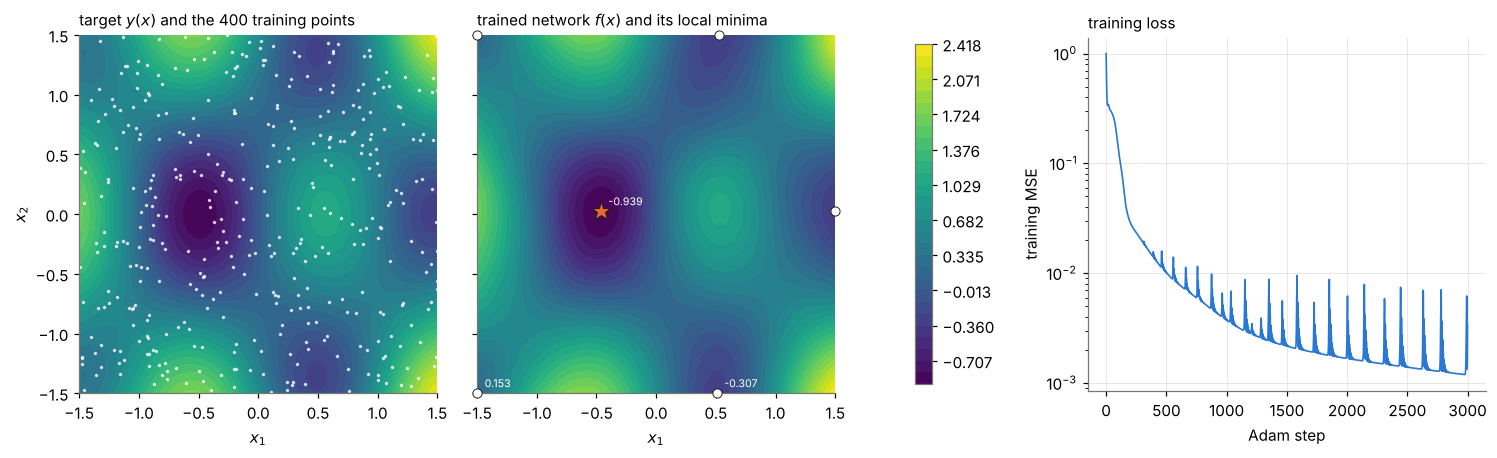

In [3]:
import jaxglobal  # noqa: F401  (switches JAX to float64 from here on; the training above is done)
from scipy.optimize import minimize as sp_minimize

surr_vg = jax.jit(jax.value_and_grad(lambda x: net(P, x)))
starts = np.stack(np.meshgrid(np.linspace(LO, HI, 7), np.linspace(LO, HI, 7)), -1).reshape(-1, 2)
local_minima = []
for s0 in starts:
    rl = sp_minimize(lambda x: [np.asarray(v, float) for v in surr_vg(jnp.asarray(x))], s0, jac=True,
                     method="L-BFGS-B", bounds=[(LO, HI)] * 2)
    if not any(np.linalg.norm(rl.x - xm) < 1e-3 for xm, _ in local_minima):
        local_minima.append((rl.x, float(rl.fun)))
local_minima.sort(key=lambda m: m[1])
print(f"{len(local_minima)} distinct local minima from {len(starts)} starts; values:",
      ", ".join(f"{v:.4f}" for _, v in local_minima))

gg = np.linspace(LO, HI, 201)
GG = jnp.asarray(np.stack(np.meshgrid(gg, gg), -1).reshape(-1, 2))
Ft = np.asarray(target(GG)).reshape(201, 201)
Fn = np.asarray(net(P, GG)).reshape(201, 201)
lev = np.linspace(min(Ft.min(), Fn.min()), max(Ft.max(), Fn.max()), 30)
fig = plt.figure(figsize=(13.5, 4.0), layout="constrained")
sub = fig.subfigures(1, 2, width_ratios=[2.1, 1])
axes = sub[0].subplots(1, 2, sharey=True)
for ax, F, title in ((axes[0], Ft, "target $y(x)$ and the 400 training points"),
                     (axes[1], Fn, "trained network $f(x)$ and its local minima")):
    cs = ax.contourf(gg, gg, F, levels=lev, cmap="viridis")
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("$x_1$")
    ax.set_aspect("equal")
    ax.grid(False)
axes[0].set_ylabel("$x_2$")
axes[0].plot(np.asarray(Xtr[:, 0]), np.asarray(Xtr[:, 1]), ".", color="white", ms=2.5, alpha=0.7)
for k, (xm, v) in enumerate(local_minima):
    axes[1].plot(*xm, "*" if k == 0 else "o", color=ORANGE if k == 0 else "white", mec=INK, mew=0.6, ms=13 if k == 0 else 6,
                 clip_on=False, zorder=3)
    axes[1].annotate(f"{v:.3f}", xm, xytext=(5, 4), textcoords="offset points", fontsize=7, color="white")
sub[0].colorbar(cs, ax=axes, shrink=0.9)
ax = sub[1].subplots()
ax.semilogy(np.asarray(hist), color=BLUE, lw=1.1)
ax.set_xlabel("Adam step")
ax.set_ylabel("training MSE")
ax.set_title("training loss", loc="left", fontsize=10)
plt.show()

## The optimization problem and its lower bounds

The problem is

$$ \min_{x \in B} f(x), \qquad B = [-1.5, 1.5]^2 . $$

It has two variables and no constraints; all the difficulty is in $f$. Each neuron applies $\tanh$, which is convex for $z<0$ and
concave for $z>0$, to an affine function of the previous layer, and the next layer adds these S-shaped pieces with weights of both
signs. The result is the landscape above, with several basins.

A spatial branch-and-bound solver splits $B$ into boxes and needs, on every box $X$, a number $\ell(X) \le \min_{x\in X} f(x)$. Boxes whose
$\ell(X)$ is above the best value found so far are discarded. How tight $\ell$ is decides how many boxes are needed. Three ways to compute it:

* **Interval arithmetic** propagates a range $[\underline z, \overline z]$ through every operation. It is cheap but forgets that all neurons of a
  layer depend on the same $x$, so the ranges grow layer by layer (the dependency problem), and its error shrinks only linearly with the box width.
* **McCormick relaxations** [mccormick1976computability] propagate a convex underestimator and a concave overestimator together with the
  interval; minimizing the convex underestimator over $X$ gives $\ell$. This is the reduced-space approach of [schweidtmann2019deterministic];
  jaxglobal builds the relaxation by interpreting the network's jaxpr operation by operation (notebook 01). Relaxations of the activation
  functions themselves are studied in [wilhelm2023convex].
* **CROWN** [zhang2018efficient] comes from neural-network verification. On the interval $[l_j, u_j]$ of each pre-activation, it bounds
  $\tanh$ by two lines,

  $$ \underline a_j z_j + \underline c_j \;\le\; \tanh(z_j) \;\le\; \overline a_j z_j + \overline c_j, \qquad z_j \in [l_j, u_j], $$

  (a tangent below and the secant above where $\tanh$ is convex, the reverse where it is concave, and a tangent through an end point
  when the interval contains 0). It then substitutes these lines backward from the output, choosing for each neuron the lower or the upper
  line by the sign of its coefficient, until $f$ is bounded by an affine function of the inputs,

  $$ f(x) \;\ge\; A^\top x + c \quad \text{on } X, \qquad\text{so}\qquad \min_{x\in X} f(x) \;\ge\; c + \sum_i \min\big(A_i \underline x_i,\; A_i \overline x_i\big). $$

  The pre-activation intervals $[l_j, u_j]$ come from interval arithmetic and are then tightened by running the same backward pass from each
  neuron, layer by layer (`jaxglobal/crown.py`). Because the substitution carries the dependence on $x$ through all layers, CROWN suffers
  less from the dependency problem than layer-by-layer propagation. jaxglobal's `crown=True` computes it on every node and keeps the larger of
  the CROWN bound and its usual bound.

The left panel shows the CROWN lines for one $\tanh$ on an interval that contains 0, together with the relaxation that `jaxglobal.relax`
builds for a lone $\tanh$ on the same interval. On an interval this wide that relaxation is much looser than the two lines; it tightens as the
interval shrinks (notebook 01 shows how). The right panel compares the three bounds on $f$ on square boxes centred at the global minimizer found
below, as the half-width shrinks: it plots the gap between the smallest value of $f$ on a $101\times101$ grid in the box and each lower bound.
The "McCormick" curve is the larger of the interval bound and 20 Frank-Wolfe steps on the convex relaxation (`jaxglobal.make_bounder`);
the solver adds bound tightening and cuts on top, so this shows the building blocks, not the solver's exact node bound.

on the whole box: min f on the grid -0.9386; lower bounds: interval -8.556, McCormick -8.556, CROWN -6.942


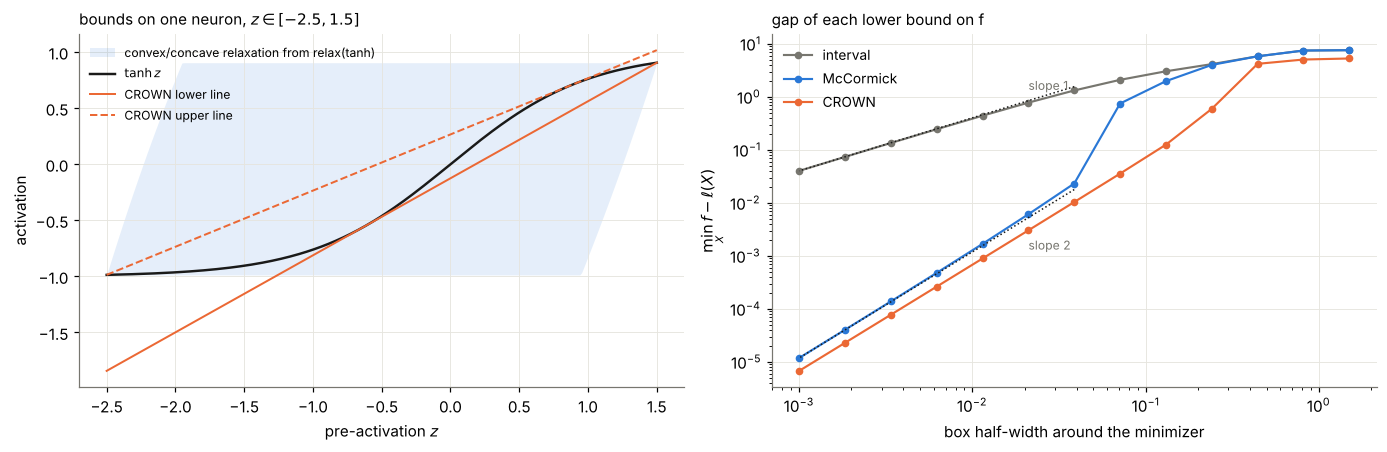

In [4]:
from jaxglobal import interval, make_bounder, relax
from jaxglobal.crown import UNARY, make_crown


def surrogate(x):
    return net(P, x)


# a feasible near-optimal point for the box centres (the best local minimum; the global solve below confirms it)
x_star = np.asarray(local_minima[0][0])
f_iv, f_mc, f_cr = jax.jit(interval(surrogate)), jax.jit(make_bounder(surrogate)), jax.jit(make_crown(surrogate))
widths = np.geomspace(1.5, 1e-3, 13)
unit = np.stack(np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 101)), -1).reshape(-1, 2)
gaps = []
for w in widths:
    blo, bhi = np.maximum(x_star - w, LO), np.minimum(x_star + w, HI)
    fmin = float(jnp.min(surrogate(jnp.asarray(blo + unit * (bhi - blo)))))
    jlo, jhi = jnp.asarray(blo), jnp.asarray(bhi)
    gaps.append([fmin - float(f_iv(jlo, jhi)[0]), fmin - float(f_mc(jlo, jhi)[0]), fmin - float(f_cr(jlo, jhi))])
gaps = np.maximum(np.array(gaps), 1e-12)
print(f"on the whole box: min f on the grid {float(Fn.min()):.4f}; lower bounds: interval {float(f_iv(jnp.full(2, LO), jnp.full(2, HI))[0]):.3f}, "
      f"McCormick {float(f_mc(jnp.full(2, LO), jnp.full(2, HI))[0]):.3f}, CROWN {float(f_cr(jnp.full(2, LO), jnp.full(2, HI))):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.0), layout="constrained")
l, u = -2.5, 1.5
zs = np.linspace(l, u, 301)
al, cl, au, cu = (float(v) for v in UNARY["tanh"](jnp.asarray(l), jnp.asarray(u)))
mc = jax.vmap(relax(lambda z: jnp.tanh(z[0])), in_axes=(0, None, None))(jnp.asarray(zs[:, None]), jnp.array([l]), jnp.array([u]))
ax1.fill_between(zs, np.asarray(mc.cv), np.asarray(mc.cc), color=BLUE, alpha=0.12, lw=0, label="convex/concave relaxation from relax(tanh)")
ax1.plot(zs, np.tanh(zs), color=INK, lw=1.6, label=r"$\tanh z$")
ax1.plot(zs, al * zs + cl, color=ORANGE, lw=1.3, label="CROWN lower line")
ax1.plot(zs, au * zs + cu, color=ORANGE, lw=1.3, ls="--", label="CROWN upper line")
ax1.set_xlabel("pre-activation $z$")
ax1.set_ylabel("activation")
ax1.set_title(f"bounds on one neuron, $z \\in [{l}, {u}]$", loc="left", fontsize=10)
ax1.legend(frameon=False, fontsize=8, loc="upper left")
for k, (lab, col) in enumerate((("interval", MUTED), ("McCormick", BLUE), ("CROWN", ORANGE))):
    ax2.loglog(widths, gaps[:, k], "o-", color=col, ms=4, lw=1.4, label=lab)
ax2.loglog(widths[6:], gaps[-1, 0] * widths[6:] / widths[-1], ":", color=INK, lw=1)
ax2.loglog(widths[6:], gaps[-1, 1] * (widths[6:] / widths[-1]) ** 2, ":", color=INK, lw=1)
ax2.text(widths[7], gaps[-1, 0] * widths[7] / widths[-1] * 1.6, "slope 1", fontsize=8, color=MUTED)
ax2.text(widths[7], gaps[-1, 1] * (widths[7] / widths[-1]) ** 2 / 4, "slope 2", fontsize=8, color=MUTED)
ax2.set_xlabel("box half-width around the minimizer")
ax2.set_ylabel(r"$\min_X f - \ell(X)$")
ax2.set_title("gap of each lower bound on f", loc="left", fontsize=10)
ax2.legend(frameon=False, fontsize=9)
plt.show()

On large boxes the interval bound is far below the true minimum (the printed whole-box values), and CROWN is the tightest of the three.
As the box shrinks, the interval gap falls in proportion to the width and the McCormick and CROWN gaps fall roughly with its square, so near the
minimizer, where branch and bound spends most of its nodes, the relaxations are much tighter than intervals. CROWN's advantage is largest on
the medium-sized boxes; this is where it can save nodes.

## jaxglobal model

The model is the network's forward function (`surrogate`, defined above). Nothing is rewritten; the weights are closed-over constants.
jaxglobal solves it in reduced space: it branches only on $x_1, x_2$.

In [5]:
rows_jax = [solve_jax(surrogate, [LO, LO], [HI, HI])]
rows_jax[0]["solver"] = "jaxglobal"
rows_jax.append(solve_jax(surrogate, [LO, LO], [HI, HI], crown=True))
rows_jax[1]["solver"] = "jaxglobal crown"
print("nodes:", rows_jax[0]["nodes"], "(default),", rows_jax[1]["nodes"], "(crown)")
table(rows_jax)

nodes: 359 (default), 231 (crown)


,solver,obj,bound,time,status
0,jaxglobal,-0.938771,-0.938772,1.07,optimal
1,jaxglobal crown,-0.938771,-0.938785,0.96,optimal


`obj` is the best value found, `bound` the proven lower bound; `optimal` means their gap is within the tolerance (relative $10^{-4}$).
Both runs find the same point. The node counts show the effect of the tighter CROWN bound on this network. The times include
compiling the bounding kernels, which is a large part of a run this small.

## Pyomo models, written by hand

**Reduced space.** The Pyomo model has the two inputs as its only variables and $f(x)$ as one nested expression, the layer equations
substituted into each other:

$$ \min_{x \in B} \; W^{(3)\top} \tanh\!\Big(W^{(2)\top} \tanh\big(W^{(1)\top} x + b^{(1)}\big) + b^{(2)}\Big) + b^{(3)} . $$

The solver sees an expression tree with 16 `tanh` nodes. It builds its relaxation by introducing its own auxiliary variables for the
subexpressions, so the user-facing model is small but the solver's internal one is not.

**Full space.** Every pre-activation and activation is a variable, and each neuron contributes two equality constraints:

$$ \begin{aligned}
   \min_{x,\,z,\,h} \;& W^{(3)\top} h^{(2)} + b^{(3)} \\
   \text{s.t.}\;& z^{(l)}_j = \textstyle\sum_i W^{(l)}_{ij} h^{(l-1)}_i + b^{(l)}_j, \quad h^{(l)}_j = \tanh\big(z^{(l)}_j\big), \qquad l = 1,2,\; j = 1,\dots,8, \\
   & h^{(0)} = x \in B, \qquad h^{(l)}_j \in [-1, 1] .
   \end{aligned} $$

That is $2 + 2\cdot 16 = 34$ variables and 32 constraints. Each nonlinear constraint is univariate, which solvers relax well, but the
relaxation of $\tanh(z_j)$ is only as good as the bounds on $z_j$. The model below gives $z_j$ no bounds; the solver has to derive them
from $x \in B$ by bound propagation before it can relax anything.

**The activation.** `pyo.tanh` is the obvious choice for the activation. With it, none of the solvers here certifies the optimum within the time limit, as the next cells show.
We therefore also write tanh as

$$ \tanh z = \frac{e^{2z} - 1}{e^{2z} + 1} = 1 - \frac{2}{e^{2z}+1}, $$

which every solver here accepts. The second form has $z$ in one place only. In the first, numerator and denominator are relaxed separately
although they move together, which gives a much weaker relaxation of the quotient.

In [6]:
def tanh_exp(z):
    return 1 - 2 / (pyo.exp(2 * z) + 1)


def reduced(tanh=pyo.tanh):
    m = pyo.ConcreteModel()
    m.x = pyo.Var(range(2), bounds=(LO, HI), initialize=0.0)
    a = [m.x[0], m.x[1]]
    for W, b in P[:-1]:
        a = [tanh(sum(W[i, j] * a[i] for i in range(W.shape[0])) + b[j]) for j in range(W.shape[1])]
    W, b = P[-1]
    m.obj = pyo.Objective(expr=sum(W[i, 0] * a[i] for i in range(W.shape[0])) + b[0])
    return m


def full(tanh=pyo.tanh):
    m = pyo.ConcreteModel()
    m.x = pyo.Var(range(2), bounds=(LO, HI), initialize=0.0)
    a = [m.x[0], m.x[1]]
    m.layers = pyo.ConstraintList()
    for l, (W, b) in enumerate(P[:-1]):
        z = pyo.Var(range(W.shape[1]), initialize=0.0)
        ao = pyo.Var(range(W.shape[1]), bounds=(-1, 1), initialize=0.0)
        setattr(m, f"z{l}", z)
        setattr(m, f"a{l}", ao)
        for j in range(W.shape[1]):
            m.layers.add(z[j] == sum(W[i, j] * a[i] for i in range(W.shape[0])) + b[j])
            m.layers.add(ao[j] == tanh(z[j]))
        a = [ao[j] for j in range(W.shape[1])]
    W, b = P[-1]
    m.obj = pyo.Objective(expr=sum(W[i, 0] * a[i] for i in range(W.shape[0])) + b[0])
    return m


size_red, size_full = model_size(reduced()), model_size(full())
print(f"reduced space: {size_red[0]} variables, {size_red[1]} constraints")
print(f"full space:    {size_full[0]} variables, {size_full[1]} constraints")

reduced space: 2 variables, 0 constraints
full space:    34 variables, 32 constraints


**How much bound propagation recovers.** The figure shows, for each neuron, the pre-activation range that interval propagation from
$x \in B$ gives (grey) and the range $z_j$ actually takes over the box (blue, from a $301\times301$ grid). In the first layer $z^{(1)}_j$ is
affine in $x$, and the interval bound is exact. In the second layer each $z^{(2)}_j$ sums eight activations that interval arithmetic treats
as independent, and the bound is several times wider than the true range. The shaded band is where $\tanh$ is not saturated; an interval that
extends well past it is relaxed by lines that are far from $\tanh$ in the middle. This is the information a full-space solver starts from,
and the reason bound tightening matters so much for full-space network models.

layer 1: interval width / true width, mean 1.00, max 1.00
layer 2: interval width / true width, mean 3.94, max 13.69


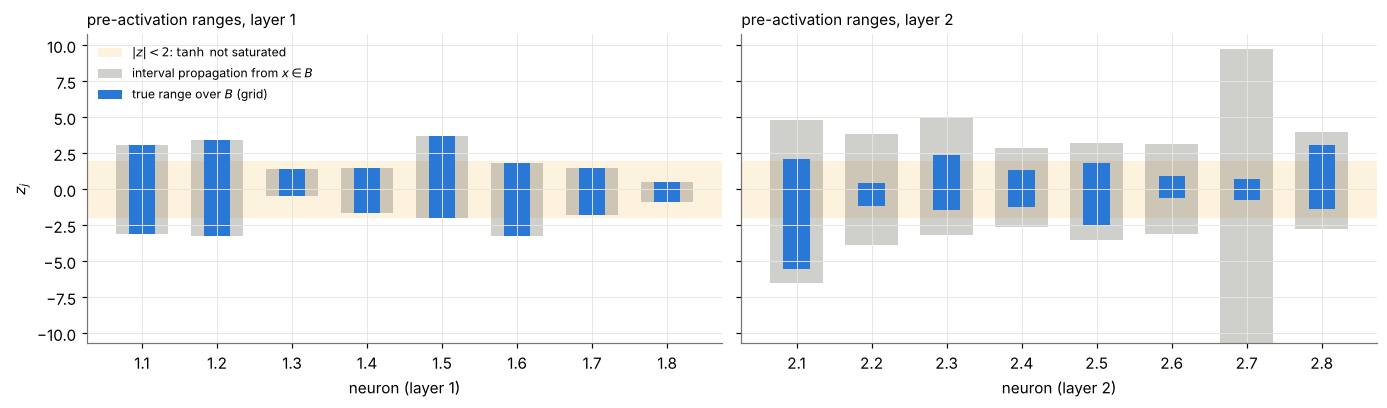

In [7]:
gs = np.linspace(LO, HI, 301)
H = np.stack(np.meshgrid(gs, gs), -1).reshape(-1, 2)
ilo, ihi = np.full(2, LO), np.full(2, HI)
z_iv, z_true = [], []
for W, b in P[:-1]:
    zc, zr = (ilo + ihi) / 2 @ W + b, (ihi - ilo) / 2 @ np.abs(W)  # interval of an affine map
    z_iv.append((zc - zr, zc + zr))
    ilo, ihi = np.tanh(zc - zr), np.tanh(zc + zr)
    Z = H @ W + b
    z_true.append((Z.min(0), Z.max(0)))
    H = np.tanh(Z)
for k in range(2):
    ratio = (z_iv[k][1] - z_iv[k][0]) / (z_true[k][1] - z_true[k][0])
    print(f"layer {k + 1}: interval width / true width, mean {ratio.mean():.2f}, max {ratio.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True, layout="constrained")
for k, ax in enumerate(axes):
    j = np.arange(len(z_iv[k][0]))
    ax.axhspan(-2, 2, color=YELLOW, alpha=0.13, lw=0, label=r"$|z| < 2$: $\tanh$ not saturated")
    ax.bar(j, z_iv[k][1] - z_iv[k][0], bottom=z_iv[k][0], width=0.7, color=MUTED, alpha=0.35, label="interval propagation from $x \\in B$")
    ax.bar(j, z_true[k][1] - z_true[k][0], bottom=z_true[k][0], width=0.35, color=BLUE, label="true range over $B$ (grid)")
    ax.set_xticks(j, [f"{k + 1}.{i + 1}" for i in j])
    ax.set_xlabel(f"neuron (layer {k + 1})")
    ax.set_title(f"pre-activation ranges, layer {k + 1}", loc="left", fontsize=10)
axes[0].set_ylabel("$z_j$")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

### Native `tanh`

Each solver gets the same limit (30 s here so the notebook stays fast; the cap for all solvers is at most 60 s).
In the tables, `obj` is the objective value the solver reports, `bound` its proven lower bound (empty if it reports none), and `status` its
termination status.

In [8]:
TL = 30
rows_tanh = []
for name, builder in (("reduced", reduced), ("full", full)):
    for s in ("scip", "couenne", "baron"):
        r = solve_pyomo(builder(pyo.tanh), s, tlim=TL)
        r["solver"] = f"{s} ({name}, tanh)"
        rows_tanh.append(r)
table(rows_tanh)

,solver,obj,bound,time,status
0,"scip (reduced, tanh)",-0.306967,-1.000000e+20,30.07,maxTimeLimit
1,"couenne (reduced, tanh)",-0.938771,NaN,31.94,maxIterations
2,"baron (reduced, tanh)",NaN,NaN,NaN,not run: GAMS/BARON not installed
3,"scip (full, tanh)",-0.938771,-3.821045e+00,30.22,maxTimeLimit
4,"couenne (full, tanh)",-0.938771,NaN,31.91,maxIterations
5,"baron (full, tanh)",NaN,NaN,NaN,not run: GAMS/BARON not installed


No run certifies the optimum. The SCIP build used here (SCIP 10 through AMPL's `.nl` interface) reads `tanh` but stops at the time limit.
Its reduced-space bound of $-10^{20}$ means no bound at all, its full-space bound is far below the optimum, and its reduced-space point can be
a local minimum rather than the global one (compare `obj` with jaxglobal's). Older SCIP `.nl` readers rejected `tanh` outright.
Couenne accepts it but does not close the gap in the time limit either (its status is a limit stop, and through `.nl` it reports no bound).
BARON (through GAMS), in an earlier run where it was installed, returned no solution for `tanh`; here it is not installed and its rows say so.
This is a solver limitation, not a modelling error: the relaxation of `tanh` is what the solvers lack, as the exponential form shows next.

### Exponential form of tanh

The same two models with `tanh_exp`. We also keep each solver's returned point, to check it against the network below.

In [9]:
def point(v):
    """The solver's values of an indexed Pyomo variable (None if it has none)."""
    vals = [pyo.value(v[i], exception=False) for i in v]
    return None if any(t is None for t in vals) else np.array(vals, float)


rows_exp, viol = [], {}
for name, builder in (("reduced", reduced), ("full", full)):
    for s in ("scip", "couenne", "baron"):
        m = builder(tanh_exp)
        r = solve_pyomo(m, s, tlim=TL)
        r["solver"] = f"{s} ({name}, exp)"
        r["x"] = point(m.x) if np.isfinite(r["obj"]) else None
        if name == "full" and r["x"] is not None:  # largest violation of the 32 neuron equations at the returned point
            viol[r["solver"]] = max(abs(pyo.value(c.body) - pyo.value(c.upper)) for c in m.layers.values())
        rows_exp.append(r)
table(rows_exp)

,solver,obj,bound,time,status
0,"scip (reduced, exp)",-0.938767,-0.938869,16.86,optimal
1,"couenne (reduced, exp)",-0.938771,NaN,31.52,maxIterations
2,"baron (reduced, exp)",NaN,NaN,NaN,not run: GAMS/BARON not installed
3,"scip (full, exp)",-0.938772,-0.938865,25.88,optimal
4,"couenne (full, exp)",-0.938771,NaN,31.81,maxIterations
5,"baron (full, exp)",NaN,NaN,NaN,not run: GAMS/BARON not installed


A status of `locallyOptimal` (BARON, if it appears) means BARON stopped without proving the gap, so its bound should not be read as certified.
Likewise a status without a finite `bound` is not a certificate, whatever the status string says.

**Reading a full-space objective.** A full-space solver reports the objective in its own activation variables $h^{(2)}$, which satisfy the
32 neuron equations only to its feasibility tolerance (about $10^{-6}$). Those small violations, carried through the layers, can shift the
reported output by more than the violation itself, so a full-space objective can come out slightly *below* the certified optimum without being
a better point. Evaluating the network itself at the solver's $x$ removes the difference. The next cell does this for every returned point:
`obj - f(x)` is the reported objective minus the network's value at the reported input, and the last column the largest equation violation.
The reduced-space models have no such equations and report the network's own value (their `obj - f(x)` is at rounding level).

In [10]:
f_np = lambda x: float(surrogate(jnp.asarray(x)))
print(f"jaxglobal: f(x*) = {rows_jax[0]['obj']:.6f}, proven lower bound {rows_jax[0]['bound']:.6f}\n")
print(f"{'solver':24s} {'obj':>11s} {'f(x)':>11s} {'obj - f(x)':>11s} {'max eq. violation':>18s}")
for r in rows_exp:
    if r["x"] is not None:
        v = viol.get(r["solver"])
        print(f"{r['solver']:24s} {r['obj']:11.6f} {f_np(r['x']):11.6f} {r['obj'] - f_np(r['x']):11.2e} {'' if v is None else f'{v:18.1e}'}")

jaxglobal: f(x*) = -0.938771, proven lower bound -0.938772

solver                           obj        f(x)  obj - f(x)  max eq. violation
scip (reduced, exp)        -0.938767   -0.938767    2.22e-16 
couenne (reduced, exp)     -0.938771   -0.938771    0.00e+00 
scip (full, exp)           -0.938772   -0.938769   -3.11e-06            8.4e-07
couenne (full, exp)        -0.938771   -0.938771   -1.11e-15            4.4e-16


## OMLT

[OMLT](https://github.com/cog-imperial/OMLT) builds these formulations from a network description, so the layer equations are not hand-written.
It is installed in this environment. We load the same weights through `NetworkDefinition`.
OMLT's formulations also carry scaled copies of the input and output variables, linked to them by equality constraints, and the full-space one
adds variables for the input and output layers, so its models are larger than the hand-written ones.

In [11]:
from omlt import OmltBlock
from omlt.neuralnet import FullSpaceSmoothNNFormulation, NetworkDefinition, ReducedSpaceSmoothNNFormulation
from omlt.neuralnet.layer import DenseLayer, InputLayer


def omlt_model(formulation_cls):
    nd = NetworkDefinition(scaled_input_bounds={0: (LO, HI), 1: (LO, HI)})
    prev = InputLayer([2])
    nd.add_layer(prev)
    for k, (W, b) in enumerate(P):
        act = "tanh" if k < len(P) - 1 else "linear"
        layer = DenseLayer([W.shape[0]], [W.shape[1]], activation=act, weights=W, biases=b)
        nd.add_layer(layer)
        nd.add_edge(prev, layer)
        prev = layer
    m = pyo.ConcreteModel()
    m.nn = OmltBlock()
    m.nn.build_formulation(formulation_cls(nd))
    m.obj = pyo.Objective(expr=m.nn.outputs[0])
    return m


rows_omlt = []
for cls in (FullSpaceSmoothNNFormulation, ReducedSpaceSmoothNNFormulation):
    sz = model_size(omlt_model(cls))
    print(f"{cls.__name__}: {sz[0]} variables, {sz[1]} constraints")
    for s in ("scip", "baron", "couenne"):
        m = omlt_model(cls)
        r = solve_pyomo(m, s, tlim=TL)
        r["solver"] = f"{s} ({cls.__name__.replace("NNFormulation", "")})"
        r["x"] = point(m.nn.inputs) if np.isfinite(r["obj"]) else None
        rows_omlt.append(r)
table(rows_omlt)

FullSpaceSmoothNNFormulation: 42 variables, 40 constraints


ReducedSpaceSmoothNNFormulation: 6 variables, 4 constraints


,solver,obj,bound,time,status
0,scip (FullSpaceSmooth),-0.938771,-3.802055e+00,30.20,maxTimeLimit
1,baron (FullSpaceSmooth),NaN,NaN,NaN,not run: GAMS/BARON not installed
2,couenne (FullSpaceSmooth),-0.938771,NaN,31.97,maxIterations
3,scip (ReducedSpaceSmooth),-0.306967,-1.000000e+20,30.04,maxTimeLimit
4,baron (ReducedSpaceSmooth),NaN,NaN,NaN,not run: GAMS/BARON not installed
5,couenne (ReducedSpaceSmooth),NaN,NaN,24.06,error: Solver (asl) did not exit normally


OMLT emits `tanh` through Pyomo, so it inherits the same solver limits as the native-`tanh` models above.
Its value is convenience (and support for ReLU big-M formulations, which need a MIP solver and are outside what jaxglobal does).
A solver that stops at its limit returns its current point, which need not satisfy the model's equations; the check below evaluates the
network at each returned input. An `obj` below jaxglobal's proven lower bound can only come from such an infeasible point.

In [12]:
for r in rows_omlt:
    if r["x"] is not None:
        print(f"{r['solver']:30s} obj {r['obj']:10.6f}   f(x) {f_np(r['x']):10.6f}   obj below the proven bound: {r['obj'] < rows_jax[0]['bound'] - 1e-6}")

scip (FullSpaceSmooth)         obj  -0.938771   f(x)  -0.938771   obj below the proven bound: False
couenne (FullSpaceSmooth)      obj  -0.938771   f(x)  -0.938771   obj below the proven bound: False
scip (ReducedSpaceSmooth)      obj  -0.306967   f(x)  -0.306967   obj below the proven bound: False


## All runs at a glance

Left: where each run ended, on the network over the whole box, for jaxglobal and the exp-form and OMLT runs (runs that returned no point are absent; the colour is the
solver, the marker the formulation). Right: wall-clock time of every run, coloured by what it returned: a certified optimum (finite proven
bound, status `optimal`), a point without a certificate, or nothing. The times come from a shared machine and include writing the model (Pyomo)
or compiling (jaxglobal); read them as orders of magnitude.

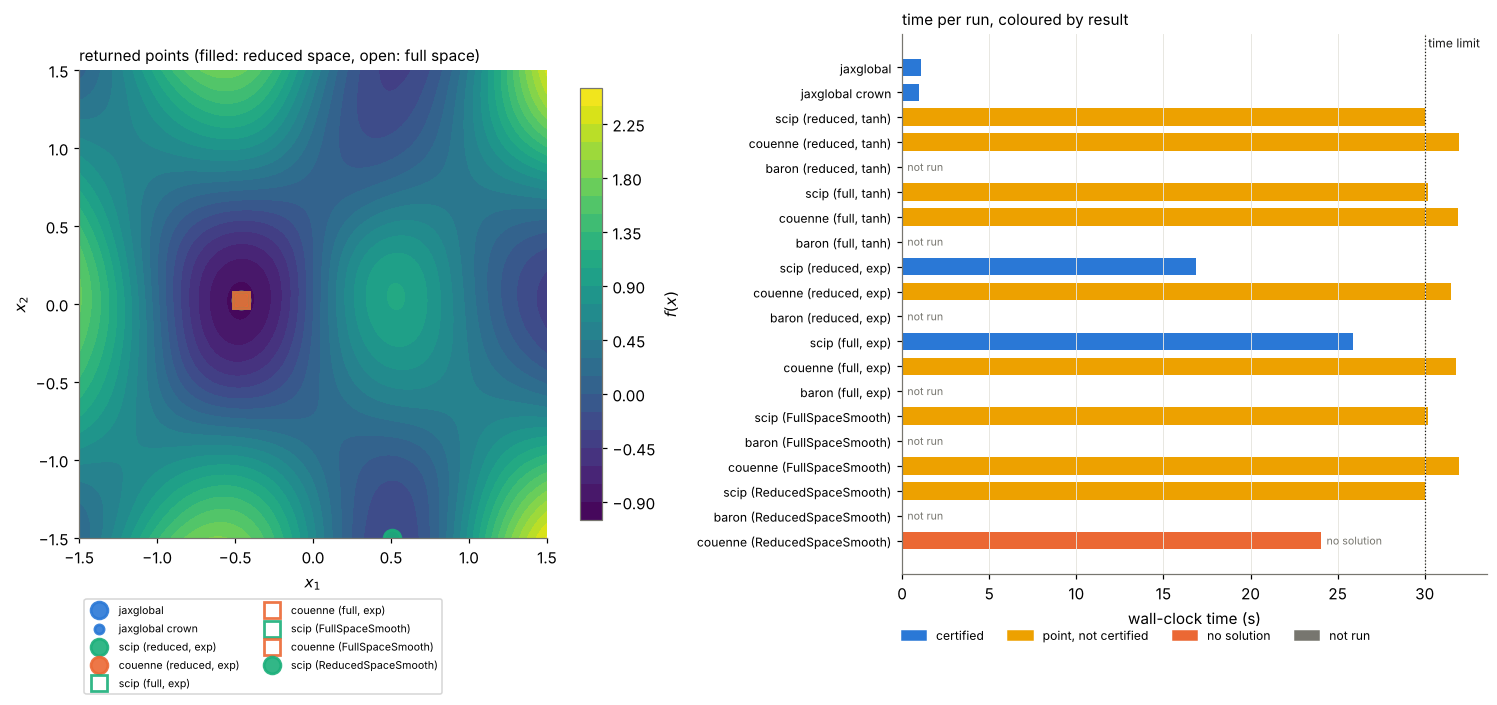

In [13]:
from matplotlib.patches import Patch

rows_all = rows_jax + rows_tanh + rows_exp + rows_omlt


def verdict(r):
    if not np.isfinite(r["obj"]):
        return "not run" if str(r["status"]).startswith("not run") else "no solution"
    return "certified" if r["status"] == "optimal" and np.isfinite(r["bound"]) else "point, not certified"


SOLVER_COLOR = {"jaxglobal": BLUE, "scip": AQUA, "couenne": ORANGE, "baron": YELLOW}
VERDICT_COLOR = {"certified": BLUE, "point, not certified": YELLOW, "no solution": ORANGE, "not run": MUTED}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 6.2), layout="constrained", gridspec_kw=dict(width_ratios=[1, 1.25]))

pts = [(r, np.asarray(r.get("x"))) for r in rows_all if r.get("x") is not None]
cs = ax1.contourf(gg, gg, Fn, levels=25, cmap="viridis")
fig.colorbar(cs, ax=ax1, shrink=0.8, label="$f(x)$")
for r, p in pts:
    name = r["solver"]
    fam = name.split()[0]
    mk = "o" if ("reduced" in name.lower() or fam == "jaxglobal") else "s"
    ax1.plot(*p, mk, ms=11 if "crown" not in name else 6, mfc="none" if mk == "s" else SOLVER_COLOR[fam], mec=SOLVER_COLOR[fam], mew=1.8,
             label=name, alpha=0.9)
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_aspect("equal")
ax1.grid(False)
ax1.set_title("returned points (filled: reduced space, open: full space)", loc="left", fontsize=10)
ax1.legend(frameon=True, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)

y = np.arange(len(rows_all))[::-1]
for yi, r in zip(y, rows_all):
    v = verdict(r)
    t = r["time"] if np.isfinite(r["time"]) else 0.0
    ax2.barh(yi, t, color=VERDICT_COLOR[v], height=0.7)
    if v in ("not run", "no solution"):
        ax2.text(t + 0.3, yi, v, va="center", fontsize=7, color=MUTED)
ax2.axvline(TL, color=INK, lw=0.8, ls=":")
ax2.text(TL, y[0] + 0.8, " time limit", fontsize=8, color=INK)
ax2.set_yticks(y, [r["solver"] for r in rows_all], fontsize=8)
ax2.set_xlabel("wall-clock time (s)")
ax2.set_title("time per run, coloured by result", loc="left", fontsize=10)
ax2.legend(handles=[Patch(color=c, label=v) for v, c in VERDICT_COLOR.items()], frameon=False, fontsize=8, ncol=4,
           loc="upper center", bbox_to_anchor=(0.4, -0.08))
ax2.grid(axis="y", visible=False)
plt.show()

In [14]:
keep = lambda tag: [r for r in rows_exp if tag in r["solver"] and not r["solver"].startswith("couenne")]
lp, lj = loc(reduced, tanh_exp), loc(surrogate)
lp_full = loc(full, tanh_exp)
save_results("11", "tanh MLP 2-8-8-1 (reduced space)", lp, lj, size_red, rows_jax + keep("reduced"), note="exp-form tanh for Pyomo; Couenne did not converge in the limit")
save_results("11", "tanh MLP 2-8-8-1 (full space)", lp_full, lj, size_full, rows_jax + keep("full"), note="exp-form tanh for Pyomo; Couenne did not converge in the limit")
print(f"lines of model code: Pyomo reduced {lp}, Pyomo full {lp_full}, jaxglobal {lj} (the network function `net` is shared with training and counted separately: {loc(net)})")

lines of model code: Pyomo reduced 11, Pyomo full 19, jaxglobal 2 (the network function `net` is shared with training and counted separately: 5)


## What was hard

**In Pyomo**

* Choosing the formulation. Reduced space has 2 variables but a deeply nested expression; full space has 34 variables and 32 constraints, with the nonconvexity pushed into simple univariate equations that solvers handle better, provided they can bound the pre-activations (see the pre-activation figure).
* The activation function. With native `tanh` no solver here certified the optimum (BARON returned nothing in the earlier run, SCIP and Couenne stop at the limit with no useful bound); the rewritten exponential form is what makes the model solvable, and you only find this out by running it.
* Every weight is re-entered as a Pyomo coefficient. A change of architecture means rewriting the builder (or using OMLT).
* Solver behaviour differs a lot on the same model (see the exp-form table and the summary figure). SCIP's results depend on its version: the SCIP 10 build used here certifies both exp-form models (see the table), while an older build did better on the full-space form and could hit the time limit on the reduced one.
  In an earlier run with GAMS installed, BARON proved the reduced-space model in a few seconds and stopped on the full-space form as `locallyOptimal` with a very weak bound. Couenne did not converge on either in the limit.
* Strengths: where a solver does converge it gives a certified bound, and the full-space form carries into a MINLP (for example, choosing among discrete designs together with the surrogate).

**In jaxglobal**

* The model is the same `net` function used for training, so there is no transcription and no chance of a mismatch between the trained network and the optimization model.
* `tanh` is a supported primitive. `crown=True` adds backward linear bounds through the layers, which tightens the bound for composed layers (see the bound-gap figure); on this network it reduced the node count (see above), but it is not guaranteed to help on every network.
* Solve times are not better than the Pyomo solvers on this size of network once compile time is included, and the wall-clock figures come from a loaded machine.
* Larger networks are the scaling concern: the number of relaxation operations grows with the number of neurons, and the dependency problem across layers weakens the bound (the second-layer pre-activation ranges above are already several times too wide).